# Handling Mixed Data

In [1]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv('E:/BRAINWORk/Machine Learning/placement-project/DataSets/titanic.csv')
df.head()

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0


In [4]:
df['number'].unique()

array(['5', '3', '6', 'A', '2', '1', '4'], dtype=object)

Text(0.5, 1.0, 'Passengers Travelling with')

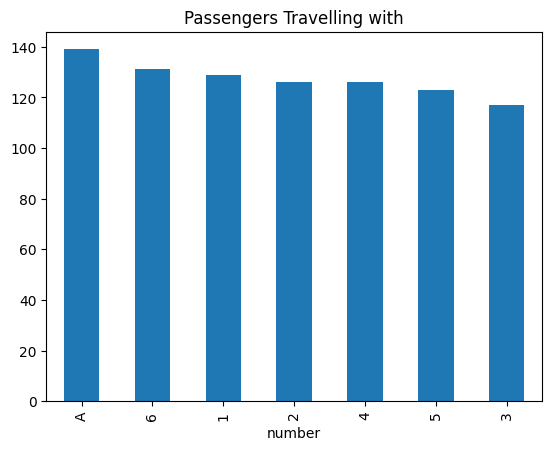

In [5]:
fig = df['number'].value_counts().plot.bar()
fig.set_title('Passengers Travelling with')

In [ ]:
# Extract Numerical Part
df['number_numerical'] = pd.to_numeric(df['number'],errors='coerce', downcast='integer')

In [7]:
# Extract Categorical Part
df['number_categorical'] = np.where(df['number_numerical'].isnull(),df['number'],np.nan)
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


In [8]:
# Extract categorical part

df['number_categorical'] = np.where(df['number_numerical'].isnull(),df['number'],np.nan)
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


In [11]:
df['Ticket'].unique()

array(['A/5 21171', 'PC 17599', 'STON/O2. 3101282', '113803', '373450',
       '330877', '17463', '349909', '347742', '237736', 'PP 9549',
       '113783', 'A/5. 2151', '347082', '350406', '248706', '382652',
       '244373', '345763', '2649', '239865', '248698', '330923', '113788',
       '347077', '2631', '19950', '330959', '349216', 'PC 17601',
       'PC 17569', '335677', 'C.A. 24579', 'PC 17604', '113789', '2677',
       'A./5. 2152', '345764', '2651', '7546', '11668', '349253',
       'SC/Paris 2123', '330958', 'S.C./A.4. 23567', '370371', '14311',
       '2662', '349237', '3101295', 'A/4. 39886', 'PC 17572', '2926',
       '113509', '19947', 'C.A. 31026', '2697', 'C.A. 34651', 'CA 2144',
       '2669', '113572', '36973', '347088', 'PC 17605', '2661',
       'C.A. 29395', 'S.P. 3464', '3101281', '315151', 'C.A. 33111',
       'S.O.C. 14879', '2680', '1601', '348123', '349208', '374746',
       '248738', '364516', '345767', '345779', '330932', '113059',
       'SO/C 14885', '31012

In [17]:
df['cabin_num'] = df['Cabin'].str.extract('(\d+)') # captures numrical prtt
df['cabin_cat'] = df['Cabin'].str[0]  # Captures the first letter
df.head()

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Snehal\AppData\Local\Temp\ipykernel_20304\2132024487.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['cabin_num'] = df['Cabin'].str.extract('(\d+)') # captures numrical prtt


,Cabin,Ticket,number,Survived,number_numerical,number_categorical,cabin_num,Cabin_cat,cabin_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN,NaN
1,C85,PC 17599,3,1,3.0,NaN,85,C,C
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN,NaN
3,C123,113803,3,1,3.0,NaN,123,C,C
4,NaN,373450,A,0,NaN,A,NaN,NaN,NaN


In [20]:
df['cabin_cat'].value_counts()

cabin_cat
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64

In [23]:
# Extract the last bit of ticket as number
df['ticket_num'] = df['Ticket'].apply(lambda s: s.split()[-1])
df['ticket_num'] = pd.to_numeric(df['ticket_num'],
                                 errors='coerce',
                                 downcast= 'integer')

# Extract the first part of ticket as category

df['ticket_cat'] = df['Ticket'].apply(lambda s: s.split()[0])
df['ticket_cat'] = np.where(df['ticket_cat'].str.isdigit(), np.nan,
                            df['ticket_cat'])
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,cabin_num,Cabin_cat,cabin_cat,ticket_num,ticket_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN,NaN,21171.0,A/5
1,C85,PC 17599,3,1,3.0,NaN,85,C,C,17599.0,PC
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN,NaN,3101282.0,STON/O2.
3,C123,113803,3,1,3.0,NaN,123,C,C,113803.0,NaN
4,NaN,373450,A,0,NaN,A,NaN,NaN,NaN,373450.0,NaN


<Axes: xlabel='cabin_cat'>

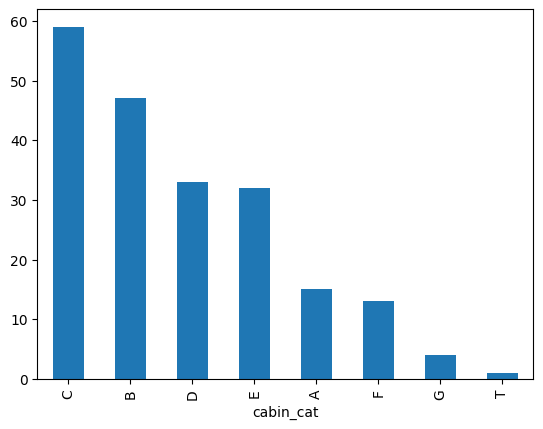

In [25]:
df['cabin_cat'].value_counts().plot(kind='bar')

# Working with date and time

In [26]:
import numpy as np
import pandas as pd

In [27]:
date = pd.read_csv('E:/BRAINWORk/Machine Learning/placement-project/DataSets/orders.csv')
time = pd.read_csv('E:/BRAINWORk/Machine Learning/placement-project/DataSets/messages.csv')

In [28]:
date.head()

,date,product_id,city_id,orders
0,2019-12-10,5628,25,3
1,2018-08-15,3646,14,157
2,2018-10-23,1859,25,1
3,2019-08-17,7292,25,1
4,2019-01-06,4344,25,3


In [29]:
time.head()

,date,msg
0,2013-12-15 00:50:00,ищу на сегодня мужика 37
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше


In [30]:
date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        1000 non-null   object
 1   product_id  1000 non-null   int64 
 2   city_id     1000 non-null   int64 
 3   orders      1000 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 31.4+ KB


In [31]:
time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    1000 non-null   object
 1   msg     1000 non-null   object
dtypes: object(2)
memory usage: 15.8+ KB


# Working with Dates

In [33]:
# Coverting to datetime datatype

date['date'] = pd.to_datetime(date['date'])
date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1000 non-null   datetime64[ns]
 1   product_id  1000 non-null   int64         
 2   city_id     1000 non-null   int64         
 3   orders      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 31.4 KB


1. Extract year from date

In [36]:
date['date_year'] = date['date'].dt.year
date.sample(5)

,date,product_id,city_id,orders,date_year,date_month_no
117,2019-05-20,1556,17,2,2019,5
820,2019-07-27,7239,22,2,2019,7
672,2019-09-18,779,16,1,2019,9
349,2018-09-02,5819,25,4,2018,9
270,2019-11-23,704,13,10,2019,11


2. Extract Month

In [35]:
date['date_month_no'] = date['date'].dt.month
date.head()

,date,product_id,city_id,orders,date_year,date_month_no
0,2019-12-10,5628,25,3,2019,12
1,2018-08-15,3646,14,157,2018,8
2,2018-10-23,1859,25,1,2018,10
3,2019-08-17,7292,25,1,2019,8
4,2019-01-06,4344,25,3,2019,1


In [37]:
date['date_month_name'] = date['date'].dt.month_name()
date.head()

,date,product_id,city_id,orders,date_year,date_month_no,date_month_name
0,2019-12-10,5628,25,3,2019,12,December
1,2018-08-15,3646,14,157,2018,8,August
2,2018-10-23,1859,25,1,2018,10,October
3,2019-08-17,7292,25,1,2019,8,August
4,2019-01-06,4344,25,3,2019,1,January


3. Extract days

In [38]:
date['date_day'] = date['date'].dt.day
date.head()

,date,product_id,city_id,orders,date_year,date_month_no,date_month_name,date_day
0,2019-12-10,5628,25,3,2019,12,December,10
1,2018-08-15,3646,14,157,2018,8,August,15
2,2018-10-23,1859,25,1,2018,10,October,23
3,2019-08-17,7292,25,1,2019,8,August,17
4,2019-01-06,4344,25,3,2019,1,January,6


In [40]:
# day of week

date['date_dow'] = date['date'].dt.dayofweek
date.head()

,date,product_id,city_id,orders,date_year,date_month_no,date_month_name,date_day,date_dow
0,2019-12-10,5628,25,3,2019,12,December,10,1
1,2018-08-15,3646,14,157,2018,8,August,15,2
2,2018-10-23,1859,25,1,2018,10,October,23,1
3,2019-08-17,7292,25,1,2019,8,August,17,5
4,2019-01-06,4344,25,3,2019,1,January,6,6


In [ ]:
# day of week-name

date['date_dow_name'] = date['date'].dt.day_name()
date.drop(columns=['product_id','city_id','orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name
0,2019-12-10,2019,12,December,10,1,Tuesday
1,2018-08-15,2018,8,August,15,2,Wednesday
2,2018-10-23,2018,10,October,23,1,Tuesday
3,2019-08-17,2019,8,August,17,5,Saturday
4,2019-01-06,2019,1,January,6,6,Sunday


In [45]:
# is weekend ?

date['date_is_weekend'] = np.where(date['date_dow_name'].isin(['sunday', 'saturday']), 1,0)
date.drop(columns=['product_id','city_id','orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,date_is_weekend
0,2019-12-10,2019,12,December,10,1,Tuesday,0
1,2018-08-15,2018,8,August,15,2,Wednesday,0
2,2018-10-23,2018,10,October,23,1,Tuesday,0
3,2019-08-17,2019,8,August,17,5,Saturday,0
4,2019-01-06,2019,1,January,6,6,Sunday,0


Extract week of the year

In [48]:
date['date_week'] = date['date'].dt.isocalendar().week
date.drop(columns=['product_id','city_id','orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,date_is_weekend,date_week
0,2019-12-10,2019,12,December,10,1,Tuesday,0,50
1,2018-08-15,2018,8,August,15,2,Wednesday,0,33
2,2018-10-23,2018,10,October,23,1,Tuesday,0,43
3,2019-08-17,2019,8,August,17,5,Saturday,0,33
4,2019-01-06,2019,1,January,6,6,Sunday,0,1


Extract Quarter

In [49]:
date['quarter'] = date['date'].dt.quarter
date.drop(columns=['product_id','city_id','orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,date_is_weekend,date_week,quarter
0,2019-12-10,2019,12,December,10,1,Tuesday,0,50,4
1,2018-08-15,2018,8,August,15,2,Wednesday,0,33,3
2,2018-10-23,2018,10,October,23,1,Tuesday,0,43,4
3,2019-08-17,2019,8,August,17,5,Saturday,0,33,3
4,2019-01-06,2019,1,January,6,6,Sunday,0,1,1



Extract semester


In [50]:
date['semester'] = np.where(date['quarter'].isin([1,2]),1,2)
date.drop(columns=['product_id','city_id','orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,date_is_weekend,date_week,quarter,semester
0,2019-12-10,2019,12,December,10,1,Tuesday,0,50,4,2
1,2018-08-15,2018,8,August,15,2,Wednesday,0,33,3,2
2,2018-10-23,2018,10,October,23,1,Tuesday,0,43,4,2
3,2019-08-17,2019,8,August,17,5,Saturday,0,33,3,2
4,2019-01-06,2019,1,January,6,6,Sunday,0,1,1,1


Extract Time Elapsed between dates

In [51]:
import datetime

today = datetime.datetime.today()
today

datetime.datetime(2026, 6, 22, 12, 42, 17, 282010)

In [54]:
(today - date['date']).dt.days

0      2386
1      2868
2      2799
3      2501
4      2724
       ... 
995    2814
996    2755
997    2603
998    2668
999    2442
Name: date, Length: 1000, dtype: int64

In [56]:
# Months passed

np.round((today - date['date']) / np.timedelta64(1, 'm'),0)

0      3436602.0
1      4130682.0
2      4031322.0
3      3602202.0
4      3923322.0
         ...    
995    4052922.0
996    3967962.0
997    3749082.0
998    3842682.0
999    3517242.0
Name: date, Length: 1000, dtype: float64

In [57]:
time

,date,msg
0,2013-12-15 00:50:00,ищу на сегодня мужика 37
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше
...,...,...
995,2012-03-16 00:50:00,ПАРЕНЬ СДЕЛАЕТ МАССАЖ ЖЕНЩИНАМ -066-877-32-44
996,2014-01-23 23:14:00,сельский п 23 ищу девушку для отношений
997,2012-10-15 23:37:00,Д+Д ДЛЯ серьезных отношений. Мой номер 093-156...
998,2012-06-21 23:34:00,7 ДНЕПР М.34 ПОЗ.С Д/Ж ДЛЯ ВСТРЕЧ.Т.098 809 15 14


In [58]:
# Converting to datetime datatype
time['date'] = pd.to_datetime(time['date'])
time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    1000 non-null   datetime64[ns]
 1   msg     1000 non-null   object        
dtypes: datetime64[ns](1), object(1)
memory usage: 15.8+ KB


In [61]:
time['hour'] = time ['date'].dt.hour
time['min'] = time ['date'].dt.minute
time['sec'] = time ['date'].dt.second
time.head()

,date,msg,hour,min,sec
0,2013-12-15 00:50:00,ищу на сегодня мужика 37,0,50,0
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826,23,40,0
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576,0,21,0
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...,0,31,0
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше,23,11,0


Extract Time Part

In [62]:
time['time'] = time['date'].dt.time
time.head()

,date,msg,hour,min,sec,time
0,2013-12-15 00:50:00,ищу на сегодня мужика 37,0,50,0,00:50:00
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826,23,40,0,23:40:00
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576,0,21,0,00:21:00
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...,0,31,0,00:31:00
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше,23,11,0,23:11:00


Time Difference


In [63]:
today - time['date']

0     4572 days 11:52:17.282010
1     4436 days 13:02:17.282010
2     4922 days 12:21:17.282010
3     4224 days 12:11:17.282010
4     4621 days 13:31:17.282010
                 ...           
995   5211 days 11:52:17.282010
996   4532 days 13:28:17.282010
997   4997 days 13:05:17.282010
998   5113 days 13:08:17.282010
999   4385 days 13:17:17.282010
Name: date, Length: 1000, dtype: timedelta64[ns]

In [64]:
# in seconds

(today - time ['date']) / np.timedelta64(1, 's')

0      3.950635e+08
1      3.833173e+08
2      4.253053e+08
3      3.649975e+08
4      3.993031e+08
           ...     
995    4.502731e+08
996    3.916133e+08
997    4.317879e+08
998    4.418105e+08
999    3.789118e+08
Name: date, Length: 1000, dtype: float64

In [65]:
# in minutes
(today - time ['date']) / np.timedelta64(1, 'm')


0      6.584392e+06
1      6.388622e+06
2      7.088421e+06
3      6.083291e+06
4      6.655051e+06
           ...     
995    7.504552e+06
996    6.526888e+06
997    7.196465e+06
998    7.363508e+06
999    6.315197e+06
Name: date, Length: 1000, dtype: float64

In [66]:
# in hour

(today - time ['date']) / np.timedelta64(1, 'h')

0      109739.871467
1      106477.038134
2      118140.354801
3      101388.188134
4      110917.521467
           ...      
995    125075.871467
996    108781.471467
997    119941.088134
998    122725.138134
999    105253.288134
Name: date, Length: 1000, dtype: float64